In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.random.seed(42)



Loading Data



In [ ]:
# from sklearn.datasets import make_moons

# X,y = make_moons(n_samples=2500, noise=0.15, random_state=42)

In [ ]:
from sklearn.datasets import load_breast_cancer

X, y = load_breast_cancer(return_X_y=True)
X = X[:500,:]
y = y[:500]

In [ ]:
#plt.scatter(X[:,0],X[:,1])

In [ ]:
from sklearn.model_selection import train_test_split

X_pretrain,X_test,y_pretrain,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)
X_train,X_val,y_train,y_val = train_test_split(X_pretrain,y_pretrain,test_size=0.2,random_state=42)

y_train = y_train.reshape(int(X_pretrain.shape[0]*0.8),1)
y_test = y_test.reshape(int(X.shape[0] * 0.2),1)

In [ ]:
X_train_mean = np.mean(X_train).reshape(1,)
X_train_std = np.std(X_train).reshape(1,)

X_train_scaled = (X_train - X_train_mean)/X_train_std
X_test_scaled = (X_test-X_train_mean)/X_train_std

Layer Definition

In [ ]:
class Layer:
    def __init__(self,fan_in,fan_out,lr):
        self.lr = lr
        self.W = np.random.randn(fan_in,fan_out) * (2/fan_in)**0.5 #(fan_in,fan_out)
        self.b = np.random.randn(1,fan_out) #(1,fan_out)
        self.X = 0 #last input #(400,fan_in)
        self.z = 0 #last pre activation value #(400,fan_out)
        self.y = 0 #last activation value #(400,fan_out)
        self.grad_W = 0 #(fan_in,fan_out)
        self.grad_b = 0 #(1,fan_out)
        self.grad_back_own = 0

    def forward_pass_linear(self,X):
        self.X = X
        self.z = self.X@self.W + self.b
        return self.z

    def forward_pass_relu(self):
        self.y = np.where(self.z < 0,0,self.z)
        return self.y

    def backward(self, grad_back):
    # Element-wise mask for ReLU activation derivative: 1 where z > 0, else 0
        relu_grad = (self.z > 0).astype(float)

        self.grad_W = (self.X.T @ (grad_back * relu_grad)) / (X_pretrain.shape[0] * 0.8)
        self.grad_b = np.mean(grad_back * relu_grad, axis=0,keepdims=True)
        self.grad_back_own = (grad_back * relu_grad) @ self.W.T

    def backward_last_layer(self,grad_back):
        self.grad_W = (self.X.T @ (grad_back * sigmoid_diff(self.z))) / (X_pretrain.shape[0] * 0.8)
        self.grad_b = np.mean(grad_back * sigmoid_diff(self.z),axis=0,keepdims=True).reshape(1,1)
        self.grad_back_own = (grad_back * sigmoid_diff(self.z)) @ self.W.T

    def update(self):
        self.W -= self.lr * self.grad_W
        self.b -= self.lr * self.grad_b

def mse_loss(y_real,y_pred):
    return (y_real - y_pred) ** 2

def mse_loss_diff(y_real,y_pred):
    return -2 * (y_real - y_pred)

def sigmoid(z):
    return 1/(1+np.exp(-z))

def sigmoid_diff(z):
    return sigmoid(z) * (1-sigmoid(z))

User Input

In [ ]:
l = int(input("Number of Layers (excluing input and output layers): "))
neuron_per_layer = [] #this list will not include input and output layers

for i in range(l):
    neuron_per_layer.append(int(input(f"Number of neurons in Layer {i+1}: ")))

layer_objects = [] #this list will contain all layers' classes

for i in range(l):
    if i==0:
        layer_objects.append(Layer(30,neuron_per_layer[i],0.05))
    else:
        layer_objects.append(Layer(neuron_per_layer[i-1],neuron_per_layer[i],0.05))

layer_objects.append(Layer(neuron_per_layer[-1],1,0.05))



Number of Layers (excluing input and output layers): 2
Number of neurons in Layer 1: 16
Number of neurons in Layer 2: 16


Training Loop


In [ ]:
epochs = 1000
losses = []
for epoch in range(epochs):
    if epoch%200 == 0:
        print(f"Training Epoch {epoch+1}..")

    #Forward Pass
    for i in range(len(layer_objects)):
        if i == 0:
            layer_objects[0].forward_pass_linear(X_train_scaled)
            layer_objects[0].forward_pass_relu()
        elif i == len(layer_objects) - 1:
            layer_objects[-1].forward_pass_linear(layer_objects[i-1].y)
            layer_objects[-1].y = sigmoid(layer_objects[-1].z)
        else:
            layer_objects[i].forward_pass_linear(layer_objects[i-1].y)
            layer_objects[i].forward_pass_relu()

    #Loss and starting grad
    loss = mse_loss(y_train,layer_objects[-1].y).reshape((int(X_pretrain.shape[0] * 0.8)),1) #(400,1)
    losses.append(np.mean(loss))
    if epoch%200 == 0:
        print(f"Training Loss: {np.mean(loss)} \n")

    starting_grad_back = mse_loss_diff(y_train,layer_objects[-1].y) #(400,1)


    #Backward Pass
    for i in range(l,-1,-1):
        if i==l:
            layer_objects[i].backward_last_layer(starting_grad_back)
        else:
            layer_objects[i].backward(layer_objects[i+1].grad_back_own)

        layer_objects[i].update()


Training Epoch 1..
Training Loss: 0.2916456716574898 

Training Epoch 201..
Training Loss: 0.06938343011523443 

Training Epoch 401..
Training Loss: 0.06415925983319895 

Training Epoch 601..
Training Loss: 0.06181028841135179 

Training Epoch 801..
Training Loss: 0.060238296272042156 



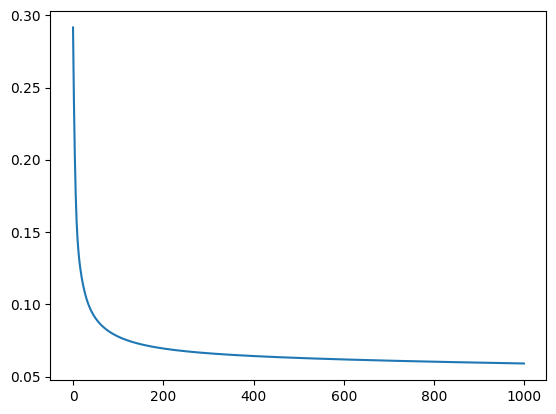

In [ ]:
plt.plot(losses)

In [ ]:
for i in range(len(layer_objects)):
    if i == 0:
        layer_objects[0].forward_pass_linear(X_test_scaled)
        layer_objects[0].forward_pass_relu()
    elif i == len(layer_objects) - 1:
        layer_objects[-1].forward_pass_linear(layer_objects[i-1].y)
        layer_objects[-1].y = sigmoid(layer_objects[-1].z)
    else:
        layer_objects[i].forward_pass_linear(layer_objects[i-1].y)
        layer_objects[i].forward_pass_relu()

y_preds_raw = layer_objects[-1].y.reshape(int(X.shape[0] * 0.2),1)

def raw_to_binary(y):
    if y>=0.5:
        return 1
    else:
        return 0
func = np.vectorize(raw_to_binary)
y_preds_binary = func(y_preds_raw).reshape(int(X.shape[0] * 0.2),1)



In [ ]:
correct = 0

for i in range(int(X.shape[0] * 0.2)):
    if y_preds_binary[i,0] == y_test[i,0]:
        correct +=1
    else:
        pass

print(f"Accuracy: {(correct * 100)/(X.shape[0] * 0.2)}%")

Accuracy: 89.0%
